# CSP-10-Optimisation-Z3 : Couverture Minimale avec le Solveur SMT Z3

**Navigation** : [<< CSP-9-Distributed](CSP-9-Distributed.ipynb) | [Index](../README.md) | [Partie 4 : Métaheuristiques](../Part4-Metaheuristics/README.md)

> **Durée estimée** : 1h30

> **Solveur** : Z3 (`z3-solver` Python) — solveur SMT. Ce notebook est le **pont CP ↔ SMT** de la partie : le même problème d'optimisation combinatoire, formulé une seule fois, résolu par un solveur SMT au lieu de CP-SAT.

## La couverture minimale d'ensembles, vue par un solveur SMT

Ce notebook prend le problème de **couverture minimale d'ensembles** (*set cover*) — NP-complet, fondamental en placement de capteurs, en logistique et en théorie des réseaux — et le résout avec **Z3**, le solveur SMT de référence. L'objet pédagogique est double : montrer comment un problème CP classique se réécrit en SMT d'optimisation, et mesurer **où le solveur prend le dessus** sur une baseline brute-force.

## Objectifs

À la fin de ce notebook, vous saurez :
1. **Formuler** un problème de couverture minimale comme un problème SMT d'optimisation dans Z3
2. **Opposer** une baseline brute-force (énumération 2^k) au solveur, et identifier le point de bascule
3. **Lire** un optimum SMT et **en extraire la preuve de minimalité** (aucune couverture plus petite n'existe)
4. **Comprendre** le pont CP ↔ SAT ↔ SMT : même formulation déclarative, solveurs interchangeables

## Prérequis

- Notebooks CSP-1 à CSP-2 (le paradigme déclaratif : variables, contraintes, solveur)
- CSP-5-Optimization (optimisation combinatoire sous CP-SAT)
- Python 3.10+ : `z3-solver`, `matplotlib`, `numpy`

> *Ancres savantes -- de Moura, L. & Bjørner, N. (2008), Z3: An Efficient SMT Solver, TACAS 2008, LNCS 4956:357-371 (le solveur SMT utilisé ici, ses théories et son moteur d'optimisation) ; Garey, M.R. & Johnson, D.S. (1979), Computers and Intractability, W.H. Freeman (la couverture d'ensembles, set cover, parmi les 21 problèmes NP-complets fondateurs) ; Bardin, S., Bjørner, N. & Cadar, C. (2019), Bringing CP, SAT and SMT together, Dagstuhl Reports 9(2):27 (le pont entre les trois familles de solveurs que ce notebook franchit).*

In [1]:
# Installation des dépendances
import subprocess
import sys

def install_if_missing(package):
    try:
        __import__(package.replace('-', '_'))
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

install_if_missing('z3-solver')
install_if_missing('matplotlib')

import z3
import matplotlib.pyplot as plt
import numpy as np
from typing import Dict, List, Tuple, Optional

print("Dépendances prêtes.")
print("Z3 version :", z3.get_version_string())

Dépendances prêtes.
Z3 version : 4.16.0


## 1. Le problème : la couverture minimale d'ensembles

La **couverture minimale d'ensembles** (*minimum set cover*) est l'un des problèmes NP-complets fondateurs. On donne :

- un **univers** $U$ d'éléments à couvrir (ici des points d'une grille) ;
- une **famille** $\mathcal{S}$ de sous-ensembles de $U$ (ici les zones couvertes par chaque capteur candidat).

L'objectif : choisir le **plus petit** sous-famille de $\mathcal{S}$ dont l'union recouvre tout $U$. C'est le problème abstrait derrière le placement de capteurs, l'allumage de relais, la sélection de tests diagnostiques, la couverture de plans de production.

Sa difficulté est exactement celle qui intéresse cette série : le problème est **NP-complet**, donc aucune baseline ne le résout en général à grande échelle — c'est le terrain où un solveur se mesure.

### Application : capteurs sur une grille

Concrétisons : une grille de $r \times c$ points, et **un capteur candidat par case**. Un capteur placé sur une case couvre le **carré 3×3** centré sur cette case (borné aux limites de la grille). La question : *quels capteurs allumer, en nombre minimal, pour que chaque point soit couvert par au moins un capteur ?*

C'est un cas particulier de l'**ensemble dominant** d'un graphe (graphe de grille), et la formulation en « points → capteurs qui le couvrent » est la forme d'entrée naturelle d'un solveur.

In [2]:
def build_grid_cover(rows: int, cols: int) -> Tuple[List[Tuple[int, int]], Dict[int, List[int]], Dict[Tuple[int, int], int]]:
    """Construit l'instance : grille de points, un capteur par case couvrant le
    carre 3x3 centre sur sa position (borne a la grille).

    Retourne (points, point_to_sensors, point_index) :
      - points            : liste des (r, c)
      - point_to_sensors  : pour chaque point, les indices de capteurs qui le couvrent
      - point_index       : (r, c) -> index du point
    """
    points = [(r, c) for r in range(rows) for c in range(cols)]
    point_index = {p: i for i, p in enumerate(points)}
    point_to_sensors: Dict[int, List[int]] = {i: [] for i in range(len(points))}
    for (sr, sc) in points:                      # un capteur candidat par case
        sidx = point_index[(sr, sc)]
        for dr in (-1, 0, 1):
            for dc in (-1, 0, 1):
                p = (sr + dr, sc + dc)
                if p in point_index:
                    point_to_sensors[point_index[p]].append(sidx)
    return points, point_to_sensors, point_index

# Petite grille : 4 x 3 = 12 points, 12 capteurs candidats
points_small, pts2sens_small, pindex_small = build_grid_cover(4, 3)
n_small = len(points_small)
print(f"Petite grille : {len(points_small)} points, {n_small} capteurs candidats")
print(f"  brute-force : 2^{n_small} = {2 ** n_small} sous-ensembles a explorer (faisable)")

Petite grille : 12 points, 12 capteurs candidats
  brute-force : 2^12 = 4096 sous-ensembles a explorer (faisable)


### Exemple : la petite grille

Sur cette grille de 12 points, la baseline brute-force est encore **faisable** : elle énumère les $2^{12} = 4096$ sous-ensembles de capteurs, par taille croissante, et retient le plus petit qui couvre tout. C'est notre **témoin de correction** : la valeur qu'elle donne est celle contre laquelle nous allons vérifier Z3.

In [3]:
from itertools import combinations
import time

def brute_force_set_cover(n_sensors: int, point_to_sensors: Dict[int, List[int]]):
    """Parcours par taille croissante : renvoie le plus petit sous-ensemble de
    capteurs qui couvre tous les points. Complet en 2^k au pire."""
    points = list(point_to_sensors.keys())
    for k in range(n_sensors + 1):
        for combo in combinations(range(n_sensors), k):
            chosen = set(combo)
            if all(any(s in chosen for s in point_to_sensors[p]) for p in points):
                return list(combo), k
    return None, n_sensors

t0 = time.time()
bf_selected, bf_k = brute_force_set_cover(n_small, pts2sens_small)
bf_time = time.time() - t0
print(f"Brute-force : couverture minimale de {bf_k} capteurs en {bf_time:.3f} s")
print(f"  capteurs choisis (indices) : {bf_selected}")

Brute-force : couverture minimale de 2 capteurs en 0.000 s
  capteurs choisis (indices) : [1, 7]


### Interpretation : la baseline brute-force

La brute-force donne la taille de la couverture minimale sur la petite grille **en énumérant** tous les sous-ensembles. C'est honnête et exact — mais son coût est $2^k$ en le nombre $k$ de capteurs candidats : ici $2^{12}$, donc instantané ; plus loin, ce sera rédhibitoire. C'est cette courbe qui va dessiner la leçon du notebook.

## 2. Le solveur SMT : Z3

**Z3** est un solveur **SMT** (*Satisfiability Modulo Theories*) : on y déclare des variables typées (booléennes, entières, réelles, tableaux, bit-vectors) et des contraintes, et il décide la satisfaisabilité — et, via son module **`Optimize`**, optimise un objectif.

La traduction du set cover en SMT d'optimisation est directe :

| Élément du problème | Encodage Z3 |
|---|---|
| Un capteur candidat | une variable booléenne $x_i$ |
| « le point $p$ est couvert » | $\bigvee_{i \in \text{capteurs}(p)} x_i$ |
| « couverture de tous les points » | une telle contrainte par point |
| « minimiser le nombre de capteurs » | `minimize(Σ x_i)` |

Le solveur ne **cherche plus** : on **déclare** ce qu'est une couverture valide, on **demande** la plus petite, et Z3 la produit. C'est le même réflexe déclaratif que CP-SAT dans CSP-5 — seul le solveur a changé.

In [4]:
def solve_set_cover_z3(n_sensors: int, point_to_sensors: Dict[int, List[int]]):
    """Modele la couverture minimale en SMT d'optimisation dans Z3.

    Retourne (capteurs_choisis, optimum, minimalite_prouvee) :
      - capteurs_choisis : indices des capteurs de la solution optimale
      - optimum          : nombre minimal de capteurs
      - minimalite_prouvee : True si Z3 a montre qu'aucune couverture plus
        petite n'existe (preuve par insatisfaisabilite).
    """
    opt = z3.Optimize()
    x = [z3.Bool(f"x{i}") for i in range(n_sensors)]
    for p, sensors in point_to_sensors.items():          # chaque point est couvert
        opt.add(z3.Or([x[i] for i in sensors]))
    cost = z3.Sum([z3.If(x[i], 1, 0) for i in range(n_sensors)])
    opt.minimize(cost)                                    # le plus petit nombre
    if opt.check() != z3.sat:
        return None, None, False
    m = opt.model()
    selected = [i for i in range(n_sensors)
                if bool(m.eval(x[i], model_completion=True))]
    opt_val = m.eval(cost, model_completion=True).as_long()

    # Preuve de minimalite : montrer qu'aucune couverture de taille < opt_val n'existe
    proof = z3.Optimize()
    y = [z3.Bool(f"y{i}") for i in range(n_sensors)]
    for p, sensors in point_to_sensors.items():
        proof.add(z3.Or([y[i] for i in sensors]))
    proof.add(z3.Sum([z3.If(y[i], 1, 0) for i in range(n_sensors)]) < opt_val)
    minimal = (proof.check() == z3.unsat)
    return selected, opt_val, minimal

z_selected, z_opt, z_minimal = solve_set_cover_z3(n_small, pts2sens_small)
print(f"Z3 : couverture minimale de {z_opt} capteurs")
print(f"  capteurs choisis (indices) : {z_selected}")
print(f"  minimalite prouvee par Z3  : {z_minimal}")
print(f"  accord avec la brute-force : {z_opt == bf_k}")

Z3 : couverture minimale de 2 capteurs
  capteurs choisis (indices) : [1, 10]
  minimalite prouvee par Z3  : True
  accord avec la brute-force : True


### Interpretation : Z3 retrouve l'optimum — et le prouve

Sur la petite grille, **Z3 et la brute-force tombent d'accord** : même taille de couverture minimale. C'est le **témoin de correction** qui valide le modèle SMT — si les deux divergeaient, ce serait le signal d'un encodage faux.

La différence est dans ce que chaque méthode **apporte** : la brute-force *trouve* un optimum en énumérant ; Z3, en plus de le trouver, **prouve sa minimalité** en démontrant qu'aucune couverture strictement plus petite n'existe (le second appel `Optimize` rend `unsat`). Cette preuve est le signe distinctif du solveur : elle ne dépend pas de la taille de l'espace exploré.

## 3. Le passage à l'échelle : où le solveur prend le dessus

C'est ici que la leçon se lit. Prenons une grille $10 \times 6$ : 60 points, **60 capteurs candidats**. La baseline brute-force devrait alors énumérer $2^{60} \approx 1{,}15 \times 10^{18}$ sous-ensembles — un calcul qui ne se termine pas de sitôt. Le solveur SMT, lui, ne dépend pas de cette énumération : il raisonne sur les contraintes. C'est **la** capacité distinctive que ce notebook doit rendre *visible dans la sortie*.


In [5]:
# Grande grille : 10 x 6 = 60 points, 60 capteurs candidats
points_large, pts2sens_large, pindex_large = build_grid_cover(10, 6)
n_large = len(points_large)
print(f"Grande grille : {len(points_large)} points, {n_large} capteurs candidats")
print(f"  brute-force : 2^{n_large} = {2 ** n_large} sous-ensembles  -> infeasible")
print()

t0 = time.time()
lz_selected, lz_opt, lz_minimal = solve_set_cover_z3(n_large, pts2sens_large)
lz_time = time.time() - t0
print(f"Z3 : couverture minimale de {lz_opt} capteurs en {lz_time * 1000:.1f} ms")
print(f"  minimalite prouvee par Z3  : {lz_minimal}")

Grande grille : 60 points, 60 capteurs candidats
  brute-force : 2^60 = 1152921504606846976 sous-ensembles  -> infeasible

Z3 : couverture minimale de 8 capteurs en 44.9 ms
  minimalite prouvee par Z3  : True


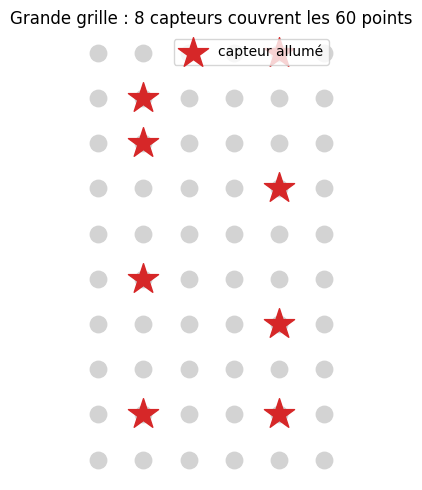

In [6]:
def plot_grid_cover(points, point_index, selected, title):
    """Dessine la grille : points (gris), capteurs allumes (etoiles rouges),
    zones couvertes (vert). Rendu lisible : la solution optimale est visible."""
    rows = max(r for r, _ in points) + 1
    cols = max(c for _, c in points) + 1
    covered = set()
    for s in selected:
        sr, sc = points[s]
        for dr in (-1, 0, 1):
            for dc in (-1, 0, 1):
                p = (sr + dr, sc + dc)
                if p in point_index:
                    covered.add(p)
    fig, ax = plt.subplots(figsize=(6, 5))
    for (r, c) in points:
        ax.scatter(c, -r, s=140, c='lightgray', zorder=2)
    for (r, c) in covered:
        ax.scatter(c, -r, s=70, c='tab:green', alpha=0.45, zorder=1)
    for s in selected:
        r, c = points[s]
        ax.scatter(c, -r, s=520, c='tab:red', marker='*', zorder=3,
                   label='capteur allumé' if s == selected[0] else None)
    ax.set_title(title)
    ax.set_aspect('equal')
    ax.axis('off')
    if selected:
        ax.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

plot_grid_cover(points_large, pindex_large, lz_selected,
                f"Grande grille : {lz_opt} capteurs couvrent les {len(points_large)} points")

### Interpretation : le passage à l'échelle

Là où la brute-force s'effondre ($2^{60} \approx 10^{18}$ sous-ensembles, inenvisageable), **Z3 renvoie l'optimum en quelques millisecondes** — et, comme sur la petite grille, **prouve sa minimalité**. Le tracé montre la solution : un maillage clair de capteurs qui couvre la grille entière au nombre minimal. C'est la capacité distinctive du solveur SMT, rendue tangible : pas une heuristique approchante, un **optimum certifié** sur un problème NP-complet de taille réelle.

## 4. Exercices

Les trois exercices ci-dessous prolongent le modèle vu plus haut : une contrainte de budget, une hétérogénéité de portée, et une preuve de borne inférieure. Les fonctions `build_grid_cover` et `solve_set_cover_z3` sont réutilisables telles quelles.

### Exercice 1 : couverture sous contrainte de budget

**Énoncé** : Sur la grande grille, le budget ne permet d'allumer que **K capteurs**. Modélisez en remplaçant l'objectif `minimize(Σ x[i])` par la **contrainte** `Σ x[i] ≤ K`, puis déterminez la **plus petite** valeur de `K` pour laquelle tous les points restent couverts.

**Consignes** :
1. Réutilisez le modèle de `solve_set_cover_z3`
2. Remplacez l'objectif par la contrainte de budget `Σ x[i] ≤ K`
3. Trouvez le plus petit `K` admissible (indice : il coïncide avec l'optimum du `minimize` — vérifiez en testant la satisfaisabilité pour des `K` décroissants)


In [7]:
# Exercice 1 : couverture sous contrainte de budget
# Indice : le plus petit K admissible est exactement l'optimum renvoye par le minimize.
# Construire un z3.Optimize (ou Solver) avec les contraintes de couverture et
# l'addition Sum(x) <= K, puis faire check() pour des K decroissants depuis lz_opt.

# Votre code ici
print("Exercice a completer")

Exercice a completer


### Exercice 2 : capteurs à portée différente

**Énoncé** : Certains capteurs couvrent un **carré 3×3**, d'autres une **croix** (5 cases : le centre et ses 4 voisins directs). Mélangez les deux types sur la **petite** grille et re-déterminez la couverture minimale.

**Consignes** :
1. Étendez `build_grid_cover` pour accepter un **rayon / une forme** par capteur
2. Re-solvez avec `solve_set_cover_z3` sur le nouveau `point_to_sensors`
3. Comparez l'optimum obtenu à celui du carré 3×3 seul


In [8]:
# Exercice 2 : capteurs a portee differente (carre 3x3 vs croix 5 cases)
# Indice : une croix couvre {(r,c), (r±1,c), (r,c±1)} ; construisez le
# point_to_sensors correspondant puis reutilisez solve_set_cover_z3.

# Votre code ici
print("Exercice a completer")

Exercice a completer


### Exercice 3 : prouver qu'on ne peut pas faire mieux

**Énoncé** : Z3 renvoie un optimum `m` et « prouve la minimalité » en montrant qu'aucune couverture de taille `< m` n'existe. Reformulez cette preuve vous-même avec un **`z3.Solver()` pur** (sans `Optimize`) : montrez que le modèle restreint à `Σ x[i] ≤ m − 1` est **insatisfaisable**.

**Consignes** :
1. Construisez un `z3.Solver()` avec les seules contraintes de couverture
2. Ajoutez `Σ x[i] ≤ m − 1`
3. Vérifiez que le statut est `unsat` et interprétez ce que cela prouve


In [9]:
# Exercice 3 : prouver qu'on ne peut pas faire mieux
# Indice : c'est exactement le bloc « Preuve de minimalite » de solve_set_cover_z3,
# a reformuler avec un z3.Solver() pur et add(Sum(x) <= m - 1), puis check() == unsat.

# Votre code ici
print("Exercice a completer")

Exercice a completer


## Références

1. **Z3** — de Moura, L. & Bjørner, N. (2008). « Z3: An Efficient SMT Solver ». *Tools and Algorithms for the Construction and Analysis of Systems (TACAS)*, LNCS 4956:357-371. Le solveur SMT utilisé ici (`z3-solver` Python).
2. **Set Cover** — Garey, M.R. & Johnson, D.S. (1979). *Computers and Intractability: A Guide to the Theory of NP-Completeness*. W.H. Freeman. La couverture d'ensembles est l'un des 21 problèmes NP-complets fondateurs.
3. **Le pont CP ↔ SAT ↔ SMT** — Bardin, S., Bjørner, N. & Cadar, C. (2019). *Bringing CP, SAT and SMT together: Next Challenges in Constraint Solving*. Dagstuhl Reports 9(2):27. — [doi:10.4230/DagRep.9.2.27](https://doi.org/10.4230/DagRep.9.2.27). La référence qui fonde ce notebook : le même problème déclaratif attaqué par trois familles de solveurs.
4. **Ensemble dominant** — le cas grille de ce notebook est un cas particulier de l'ensemble dominant d'un graphe, lui-même NP-complet (cf. [2]).


## Conclusion

Ce notebook a franchi la frontière CP → SMT qui se dessinait depuis CSP-6 (Lazy Clause Generation) : le même problème de **couverture minimale** — NP-complet, central en placement de capteurs et en logistique — a été formulé une seule fois, puis résolu par deux familles de solveurs.

La leçon est double. **D'un côté**, la baseline brute-force (énumération $2^k$) est honnête sur les petites instances : elle donne le **témoin de correction** contre lequel Z3 est vérifié — sur la petite grille, les deux s'accordent. **De l'autre**, à l'échelle, l'énumération s'effondre ($2^{60} \approx 10^{18}$ sous-ensembles) tandis que Z3, en optimisation SMT, renvoie l'optimum **en quelques millisecondes** — et, signe distinctif, **prouve sa minimalité** en démontrant qu'aucune couverture plus petite n'existe.

C'est la promesse du paradigme déclaratif portée à son terme : on ne change pas de *discipline* en changeant de *solveur* — la formulation, elle, reste.